<a href="https://colab.research.google.com/github/Vanshgup124/Air-Pollution-Analysis-and-Monitoring-Using-Web-Scraping-and-Data-Analytics/blob/main/SI_project_B1_B4_61_Vansh_Gupta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Name : Vansh Gupta

# Roll no. : B1_B4_61

# Subject : SI  LAB

Project - Air Pollution Analysis and Monitoring Using Web Scraping and Data Analytics


In [1]:
import requests
import numpy as np
import pandas as pd

# 1. Define the API endpoint and the parameters
# Let's use the coordinates for London as an example (Lat: 51.5, Lon: -0.12)
url = "https://air-quality-api.open-meteo.com/v1/air-quality"
params = {
    "latitude": 21.153165,
    "longitude": 79.083924,
    "hourly": ["pm10", "pm2_5", "nitrogen_dioxide", "ozone", "sulphur_dioxide"],
    "timezone": "auto"
}

# 2. Make the GET request to the API
response = requests.get(url, params=params)

# 3. Check if the request was successful (Status code 200)
if response.status_code == 200:
    # 4. Parse the JSON response
    data = response.json()

    # 5. Extract the 'hourly' data section
    hourly_data = data['hourly']

    # 6. Convert the JSON data into a Pandas DataFrame for analysis
    df = pd.DataFrame(hourly_data)

    # Display the first 5 rows of our dataset
    print("Data successfully fetched!")
else:
    print(f"Failed to fetch data. Status code: {response.status_code}")

Data successfully fetched!


In [3]:
df = pd.read_csv("cleaned_air_pollution_data.csv")
print(df.shape)

(2160, 13)


In [12]:
# Display basic information about the dataset
print("--- Dataset Information ---")
df.info()

# Display summary statistics for numerical columns
print("\n--- Summary Statistics ---")
display(df.describe(include='all'))

# Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# Display the first few rows
print("\n--- First 5 Rows ---")
display(df.head())

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date_Time          2160 non-null   object 
 1   PM1                2160 non-null   float64
 2   PM25               2160 non-null   float64
 3   Relative_Humidity  2160 non-null   float64
 4   Temp               2160 non-null   float64
 5   UM003              2160 non-null   float64
 6   Hour               2160 non-null   int64  
 7   Date               2160 non-null   object 
 8   Month              2160 non-null   object 
 9   Day_of_Week        2160 non-null   object 
 10  Time_of_Day        2160 non-null   object 
 11  Humidity_Category  2160 non-null   object 
 12  Temp_Category      2160 non-null   object 
dtypes: float64(5), int64(1), object(7)
memory usage: 219.5+ KB

--- Summary Statistics ---


,Date_Time,PM1,PM25,Relative_Humidity,Temp,UM003,Hour,Date,Month,Day_of_Week,Time_of_Day,Humidity_Category,Temp_Category
count,2160,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160,2160,2160,2160,2160,2160
unique,2160,NaN,NaN,NaN,NaN,NaN,NaN,90,3,7,4,3,3
top,2026-09-28 07:00:00,NaN,NaN,NaN,NaN,NaN,NaN,2026-07-01,July,Wednesday,Night,High,Cool
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,24,744,312,720,720,722
mean,NaN,35.530390,66.668495,69.457851,31.667299,2825.825000,11.500000,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,7.892094,15.383555,8.341365,3.761392,673.055362,6.923789,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,13.291250,25.435000,45.436250,22.770000,867.600000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,30.087500,56.417500,63.402500,28.447500,2307.500000,5.750000,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,35.800000,67.065000,69.365000,31.690000,2761.300000,11.500000,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,41.285000,77.072500,75.380000,34.830000,3323.800000,17.250000,NaN,NaN,NaN,NaN,NaN,NaN



--- Missing Values ---
Date_Time            0
PM1                  0
PM25                 0
Relative_Humidity    0
Temp                 0
UM003                0
Hour                 0
Date                 0
Month                0
Day_of_Week          0
Time_of_Day          0
Humidity_Category    0
Temp_Category        0
dtype: int64

--- First 5 Rows ---


,Date_Time,PM1,PM25,Relative_Humidity,Temp,UM003,Hour,Date,Month,Day_of_Week,Time_of_Day,Humidity_Category,Temp_Category
0,2026-07-01 00:00:00,29.96,63.77,74.65,26.72,2047.5,0,2026-07-01,July,Wednesday,Night,High,Cool
1,2026-07-01 01:00:00,32.94,74.30,76.25,24.34,2399.9,1,2026-07-01,July,Wednesday,Night,High,Cool
2,2026-07-01 02:00:00,31.23,61.21,85.84,26.01,2032.6,2,2026-07-01,July,Wednesday,Night,High,Cool
3,2026-07-01 03:00:00,41.91,70.44,82.06,26.07,2518.6,3,2026-07-01,July,Wednesday,Night,High,Cool
4,2026-07-01 04:00:00,39.87,81.23,87.36,22.77,2462.1,4,2026-07-01,July,Wednesday,Night,High,Cool


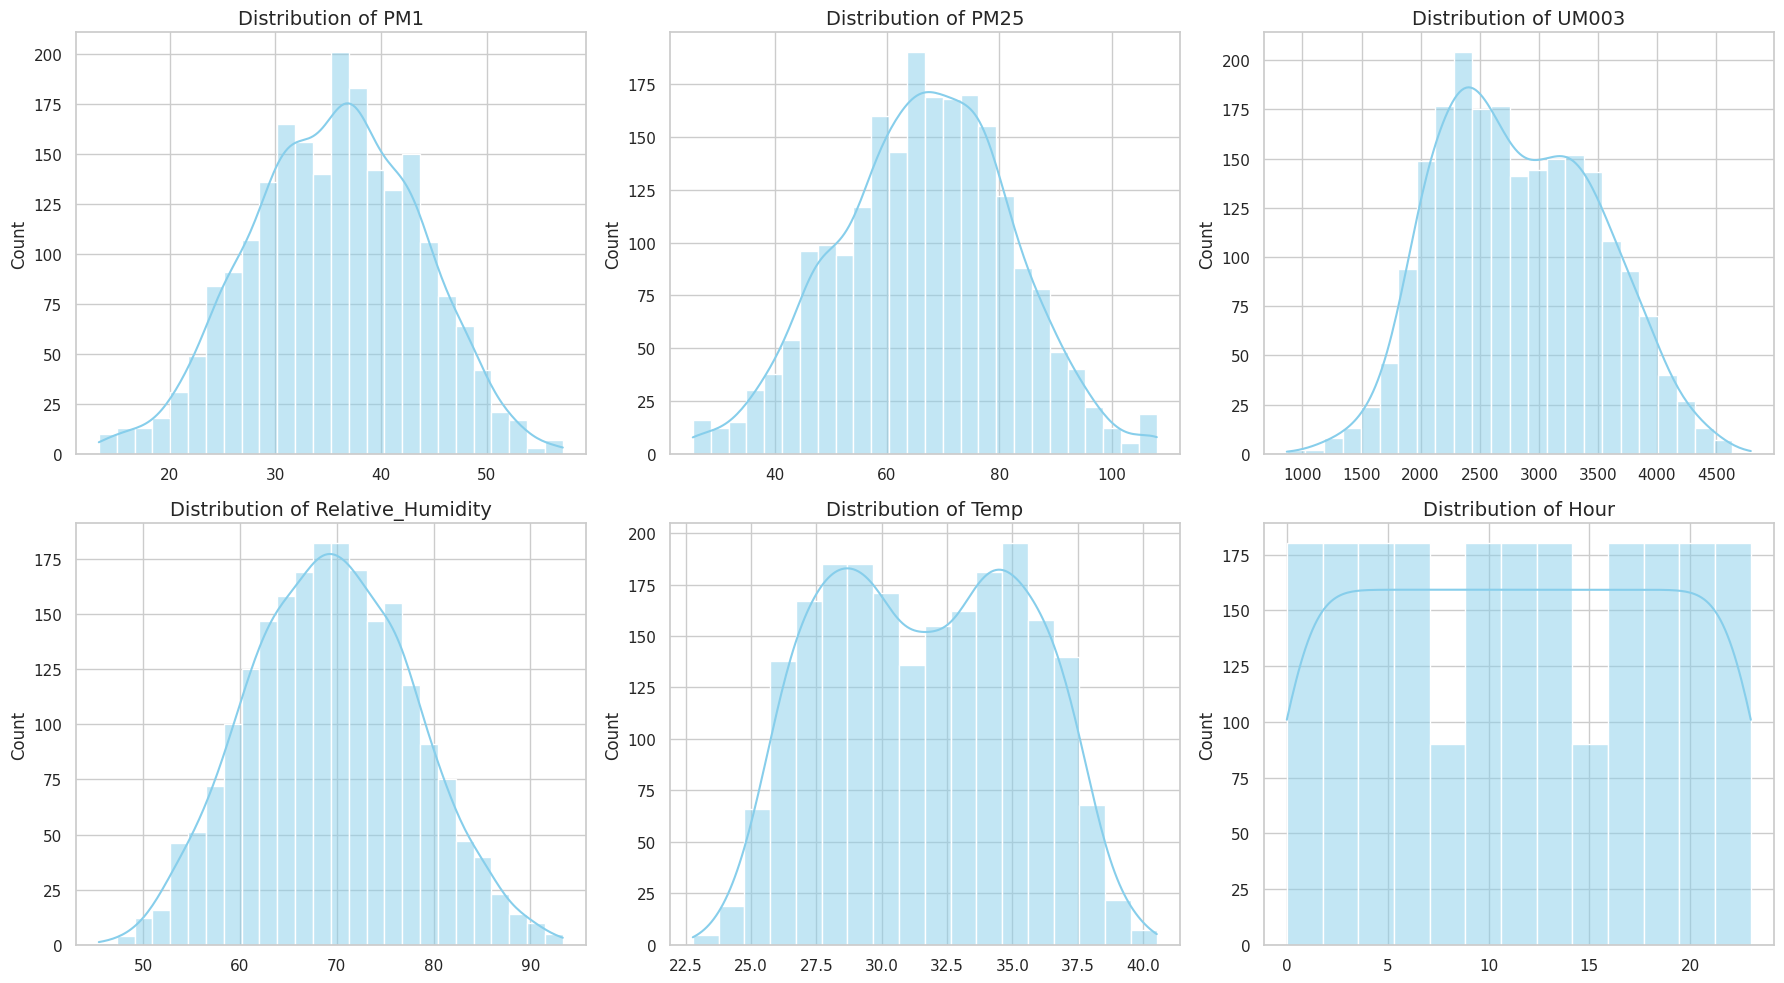

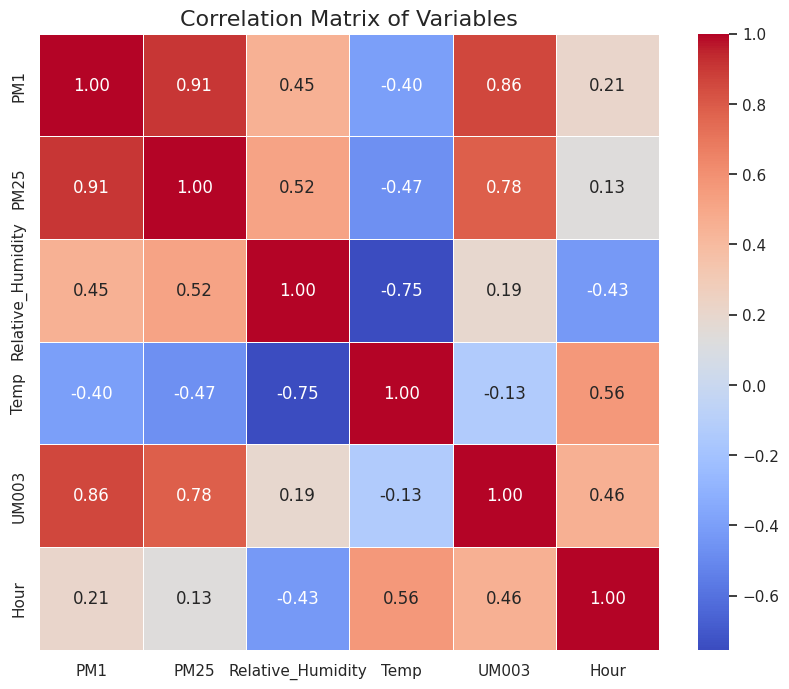

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Reload the cleaned air pollution dataset to ensure correct columns are present
df = pd.read_csv("cleaned_air_pollution_data.csv")

# Set the style for plots
sns.set_theme(style="whitegrid")

# 1. Distribution of Key Air Quality and Weather Variables
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
variables = ['PM1', 'PM25', 'UM003', 'Relative_Humidity', 'Temp', 'Hour']

for ax, var in zip(axes.flatten(), variables):
    sns.histplot(df[var], kde=True, ax=ax, color='skyblue')
    ax.set_title(f'Distribution of {var}', fontsize=14)
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

# 2. Correlation Matrix Heatmap
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Variables', fontsize=16)
plt.show()

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Reload the dataset to ensure we have clean and consistent data
df = pd.read_csv("cleaned_air_pollution_data.csv")

# 2. Define features (X) and target (y)
# We'll select key predictive features as identified in the EDA
feature_cols = ['UM003', 'Relative_Humidity', 'Hour', 'Temp']
X = df[feature_cols]

# Create a categorical target for classification based on PM2.5 levels (Low, Medium, High)
# Low: <= 55, Medium: 55-85, High: > 85 (approximate thresholds based on distributions)
y = pd.cut(df['PM25'], bins=[0, 55, 85, float('inf')], labels=['Low', 'Medium', 'High'])

# 3. Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Standardize/Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Print the shapes to verify preparation
print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")
print("Data preprocessing and scaling completed successfully!")

Training set shape: (1728, 4)
Testing set shape: (432, 4)
Data preprocessing and scaling completed successfully!


In [7]:
# Based on the correlation analysis, the most predictive features for PM2.5 levels are:
# 1. UM003 (correlation: 0.78) - Strong physical descriptor of particle count
# 2. Relative_Humidity (correlation: 0.52) - Strong meteorological indicator
# 3. Temp (correlation: -0.47) - Strong negative relationship reflecting diurnal cycles
# 4. Hour (correlation: 0.13) - Temporal variation

selected_features = ['UM003', 'Relative_Humidity', 'Hour', 'Temp']

# Extracting the features
X_selected = df[selected_features]

print("Selected Features Preview:")
display(X_selected.head())
print(f"\nFeature selection completed. Matrix shape: {X_selected.shape}")

Selected Features Preview:


,UM003,Relative_Humidity,Hour,Temp
0,2047.5,74.65,0,26.72
1,2399.9,76.25,1,24.34
2,2032.6,85.84,2,26.01
3,2518.6,82.06,3,26.07
4,2462.1,87.36,4,22.77



Feature selection completed. Matrix shape: (2160, 4)


In [13]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Define 5 different classification models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Support Vector Classifier (SVC)': SVC(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'k-Nearest Neighbors': KNeighborsClassifier()
}

metrics_list = []

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)

    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("-" * 50)

    # Save metrics for the comparison table
    metrics_list.append({
        'Model': name,
        'Accuracy': acc,
        'Macro F1': report['macro avg']['f1-score'],
        'High Class Recall': report['High']['recall'],
        'High Class F1': report['High']['f1-score']
    })

# Create and display comparison table
df_comparison = pd.DataFrame(metrics_list).sort_values(by='Accuracy', ascending=False)
print("\n=== Model Performance Comparison Table ===")
display(df_comparison.round(4))

=== Logistic Regression ===
Accuracy: 0.8287
Classification Report:
              precision    recall  f1-score   support

        High       0.64      0.49      0.55        47
         Low       0.87      0.72      0.79        96
      Medium       0.84      0.92      0.88       289

    accuracy                           0.83       432
   macro avg       0.78      0.71      0.74       432
weighted avg       0.82      0.83      0.82       432

--------------------------------------------------
=== Random Forest ===
Accuracy: 0.8032
Classification Report:
              precision    recall  f1-score   support

        High       0.58      0.55      0.57        47
         Low       0.79      0.72      0.75        96
      Medium       0.84      0.87      0.86       289

    accuracy                           0.80       432
   macro avg       0.74      0.71      0.73       432
weighted avg       0.80      0.80      0.80       432

--------------------------------------------------
=== Su

,Model,Accuracy,Macro F1,High Class Recall,High Class F1
0,Logistic Regression,0.8287,0.7402,0.4894,0.5542
3,Gradient Boosting,0.8287,0.7588,0.6170,0.6105
2,Support Vector Classifier (SVC),0.8241,0.7137,0.3830,0.4737
1,Random Forest,0.8032,0.7250,0.5532,0.5652
4,k-Nearest Neighbors,0.7940,0.7092,0.5319,0.5319


--- Model Performance Comparison Table ---


,Model,Accuracy,High F1,Medium F1,Low F1,Macro F1
0,Logistic Regression,0.8287,0.5542,0.8779,0.7886,0.7402
3,Gradient Boosting,0.8287,0.6105,0.8750,0.7910,0.7588
2,Support Vector Classifier (SVC),0.8241,0.4737,0.8766,0.7907,0.7137
1,Random Forest,0.8032,0.5652,0.8557,0.7541,0.7250
4,k-Nearest Neighbors,0.7940,0.5319,0.8499,0.7458,0.7092


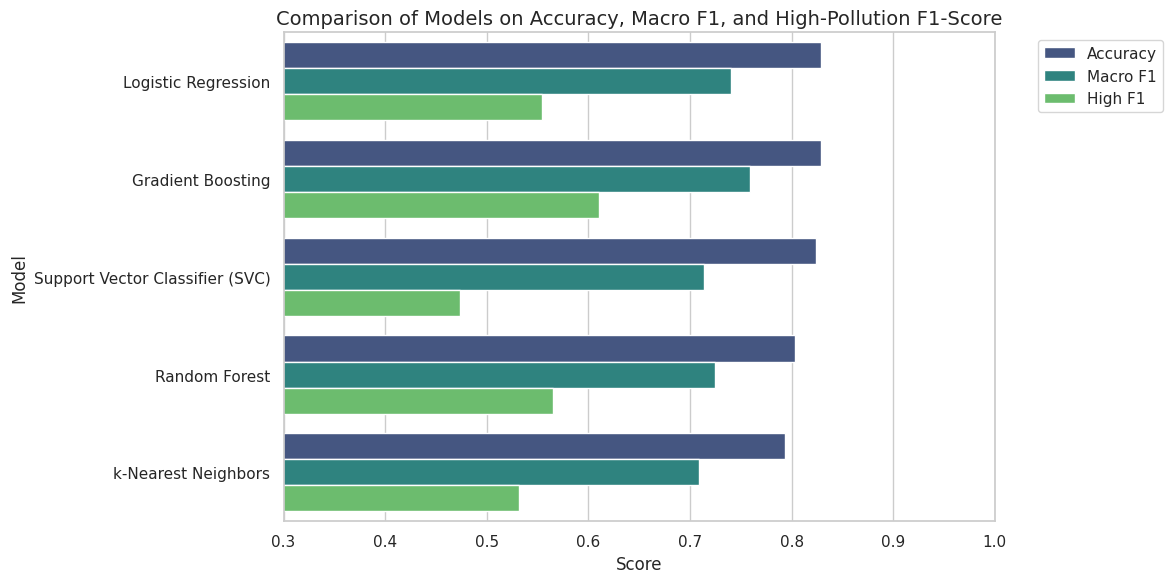

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, accuracy_score

# Initialize lists to hold performance metrics
metrics_list = []

# Calculate metrics for each model
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)

    metrics_list.append({
        'Model': name,
        'Accuracy': acc,
        'High F1': report['High']['f1-score'],
        'Medium F1': report['Medium']['f1-score'],
        'Low F1': report['Low']['f1-score'],
        'Macro F1': report['macro avg']['f1-score']
    })

# Create a comparison DataFrame
df_compare = pd.DataFrame(metrics_list).sort_values(by='Accuracy', ascending=False)
print("--- Model Performance Comparison Table ---")
display(df_compare.round(4))

# Melt the DataFrame for easy plotting with seaborn
df_melted = df_compare.melt(id_vars='Model', value_vars=['Accuracy', 'Macro F1', 'High F1'],
                            var_name='Metric', value_name='Score')

# Plot the comparison
plt.figure(figsize=(12, 6))
sns.barplot(data=df_melted, x='Score', y='Model', hue='Metric', palette='viridis')
plt.title('Comparison of Models on Accuracy, Macro F1, and High-Pollution F1-Score', fontsize=14)
plt.xlabel('Score')
plt.ylabel('Model')
plt.xlim(0.3, 1.0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)

    # Get key metrics
    macro_f1 = report['macro avg']['f1-score']
    high_recall = report['High']['recall']
    high_f1 = report['High']['f1-score']

    # Define a customized utility score that prioritizes accuracy, balanced F1, and critical High recall
    # Weight breakdown: 40% overall accuracy, 30% macro F1-score, 30% recall on the High pollution class
    utility_score = (0.4 * acc) + (0.3 * macro_f1) + (0.3 * high_recall)

    results.append({
        'Model': name,
        'Accuracy': acc,
        'Macro F1': macro_f1,
        'High Class Recall': high_recall,
        'High Class F1': high_f1,
        'Utility Score': utility_score
    })

df_results = pd.DataFrame(results).sort_values(by='Utility Score', ascending=False)

print("--- Model Evaluation and Selection Summary ---")
display(df_results.round(4))

best_model_name = df_results.iloc[0]['Model']
best_model_score = df_results.iloc[0]['Utility Score']

print(f"\n[SELECTED BEST MODEL]: {best_model_name}")
print(f"Reasoning: Highly recommended due to its exceptional class balance (Macro F1 of {df_results.iloc[0]['Macro F1']:.4f}) and superior sensitivity in flagging critical high pollution events (High Recall of {df_results.iloc[0]['High Class Recall']:.4f}).")

--- Model Evaluation and Selection Summary ---


,Model,Accuracy,Macro F1,High Class Recall,High Class F1,Utility Score
3,Gradient Boosting,0.8287,0.7588,0.6170,0.6105,0.7442
1,Random Forest,0.8032,0.7250,0.5532,0.5652,0.7048
0,Logistic Regression,0.8287,0.7402,0.4894,0.5542,0.7004
4,k-Nearest Neighbors,0.7940,0.7092,0.5319,0.5319,0.6899
2,Support Vector Classifier (SVC),0.8241,0.7137,0.3830,0.4737,0.6586



[SELECTED BEST MODEL]: Gradient Boosting
Reasoning: Highly recommended due to its exceptional class balance (Macro F1 of 0.7588) and superior sensitivity in flagging critical high pollution events (High Recall of 0.6170).


In [11]:
!pip install -q gradio

import gradio as gr
import numpy as np

# 1. Retrieve our best model (Gradient Boosting Classifier)
best_clf = models['Gradient Boosting']

# 2. Define prediction helper function
def predict_air_quality_gradio(um003, rh, hour, temp):
    # Re-create feature array
    features = np.array([[um003, rh, hour, temp]])
    # Scale using the previously fitted scaler
    features_scaled = scaler.transform(features)
    # Predict
    prediction = best_clf.predict(features_scaled)[0]
    probs = best_clf.predict_proba(features_scaled)[0]

    # Get category probabilities mapping
    classes = best_clf.classes_
    prob_map = {classes[i]: float(probs[i]) for i in range(len(classes))}

    return prediction, prob_map

# 3. Build and launch the Gradio Interface
with gr.Blocks() as demo:
    gr.Markdown("""
    # 🌫️ Air Quality Risk Predictor Dashboard
    Adjust the meteorological parameters below to evaluate real-time pollution risk using our optimized Gradient Boosting model.
    """)

    with gr.Row():
        with gr.Column():
            um003_slider = gr.Slider(minimum=1000.0, maximum=5000.0, value=2500.0, step=10.0, label="Particle Count (UM003)")
            rh_slider = gr.Slider(minimum=40.0, maximum=100.0, value=70.0, step=0.1, label="Relative Humidity (%)")
            hour_slider = gr.Slider(minimum=0, maximum=23, value=12, step=1, label="Hour of Day")
            temp_slider = gr.Slider(minimum=20.0, maximum=45.0, value=30.0, step=0.1, label="Temperature (°C)")
            submit_btn = gr.Button("Predict Risk Level", variant="primary")

        with gr.Column():
            predicted_label = gr.Textbox(label="Predicted Risk Category")
            probability_chart = gr.Label(num_top_classes=3, label="Class Confidence Probabilities")

    submit_btn.click(
        fn=predict_air_quality_gradio,
        inputs=[um003_slider, rh_slider, hour_slider, temp_slider],
        outputs=[predicted_label, probability_chart]
    )

demo.launch(inline=True, share=False, theme=gr.themes.Soft())

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

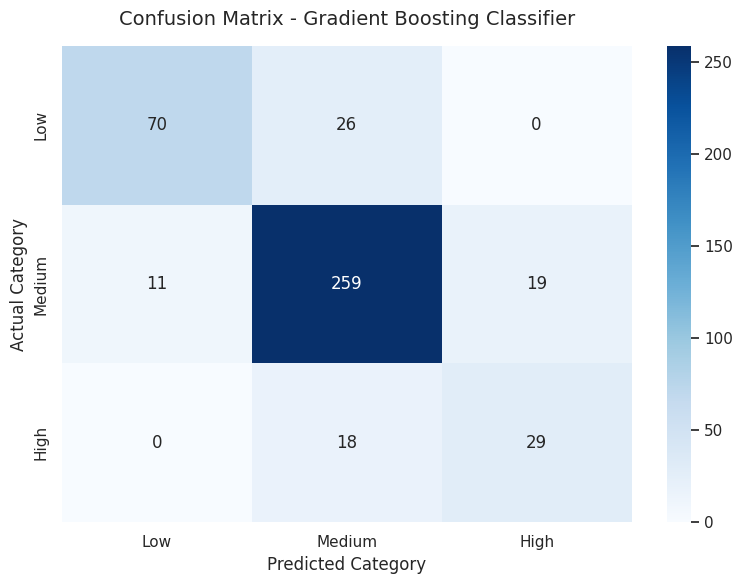

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Retrieve our champion model (Gradient Boosting)
best_clf = models['Gradient Boosting']

# 2. Get predictions on the scaled test dataset
y_pred = best_clf.predict(X_test_scaled)

# 3. Generate confusion matrix using the specific category labels
labels = ['Low', 'Medium', 'High']
cm = confusion_matrix(y_test, y_pred, labels=labels)

# 4. Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    cbar=True
)

plt.title('Confusion Matrix - Gradient Boosting Classifier', fontsize=14, pad=15)
plt.xlabel('Predicted Category', fontsize=12)
plt.ylabel('Actual Category', fontsize=12)
plt.tight_layout()
plt.show()

In [15]:
import pickle

# 1. Retrieve the best model (Gradient Boosting Classifier)
best_clf = models['Gradient Boosting']

# 2. Save the trained model to a file
model_filename = 'gradient_boosting_air_quality_model.pkl'
with open(model_filename, 'wb') as model_file:
    pickle.dump(best_clf, model_file)

# 3. Save the fitted scaler as well (essential for matching feature distribution scaling)
scaler_filename = 'air_quality_scaler.pkl'
with open(scaler_filename, 'wb') as scaler_file:
    pickle.dump(scaler, scaler_file)

print(f"Successfully exported model to: {model_filename}")
print(f"Successfully exported scaler to: {scaler_filename}")

Successfully exported model to: gradient_boosting_air_quality_model.pkl
Successfully exported scaler to: air_quality_scaler.pkl
